# Figure 8-5 — worst case

Resistors are ±0.1% and capacitors are ±1%. Those five independent
tolerances have 32 corners. Offset is ±200 µV and each bias current is
±10 pA. Offset and bias current move the DC output. They do not move the
linear transfer from Vin.

The transient table lists every corner for the analytical model, ngspice,
and LTspice at 250 kHz, 1 V peak. The ideal voltage-controlled source is
used so the three columns are the same linear circuit.

Created with Grok Build.


In [1]:
import sys

import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import io
from pathlib import Path
from IPython.display import display, Image

def _show(*args, **kwargs):
    buf = io.BytesIO()
    fig = plt.gcf()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    plt.close("all")
    display(Image(data=buf.getvalue()))

plt.show = _show

def _find_project_root():
    start = Path.cwd().resolve()
    named = Path("Sections/Electronics/Analog_and_Digital/OPA365_Fig85")
    candidates = [start, *start.parents, start / named]
    if start.name == "notebooks":
        candidates.insert(0, start.parent)
    for cand in candidates:
        if (cand / "mfb_design" / "__init__.py").is_file():
            return cand
    raise FileNotFoundError("mfb_design package was not found")

ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [2]:
from mfb_design.params import CircuitParams, ToleranceSpec

p = CircuitParams(
    R1=549.0,
    R2=1.24e3,
    R3=549.0,
    C1=1.0e-9,
    C2=150.0e-12,
    r_tol=ToleranceSpec(0.001),
    c_tol=ToleranceSpec(0.01),
)
SPICE_WORKERS = 4
N_MC_AC = 2000
N_MC_TRAN = 500
MC_SEED = 42
print(
    f"R1={p.R1:g} ohm  R2={p.R2:g} ohm  R3={p.R3:g} ohm  "
    f"C1={p.C1:g} F  C2={p.C2:g} F"
)
print(
    f"supplies {p.op.v_pos:g} V / {p.op.v_neg:g} V, "
    f"tone {p.op.f_passband_hz:g} Hz, {p.op.v_in_peak:g} V peak"
)
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


R1=549 ohm  R2=1240 ohm  R3=549 ohm  C1=1e-09 F  C2=1.5e-10 F
supplies 2.5 V / -2.5 V, tone 250000 Hz, 1 V peak


In [3]:
from mfb_design.worst_case import analytical_worst_case, rss_bounds, spice_wc_corners

wc = analytical_worst_case(p, include_opamp=True)
keys = ["fc_hz", "gain_at_passband", "phase_at_passband_deg", "dc_error", "gain_error"]
summary = pd.DataFrame({
    "metric": keys,
    "nominal": [wc.nominal[k] for k in keys],
    "minimum": [wc.minimum[k] for k in keys],
    "maximum": [wc.maximum[k] for k in keys],
})
display(summary)
rss = rss_bounds(p, metrics=("fc_hz", "dc_error", "gain_at_passband"), include_opamp=True)
display(pd.DataFrame(rss).T)
print(
    f"fc span {wc.span('fc_hz'):.1f} Hz, "
    f"DC error span {wc.span('dc_error')*1e6:.1f} µV"
)


,metric,nominal,minimum,maximum
0,fc_hz,495372.696835,489978.038629,500877.338788
1,gain_at_passband,0.967223,0.964306,0.970113
2,phase_at_passband_deg,136.346270,135.818520,136.872166
3,dc_error,0.000000,-0.000400,0.000400
4,gain_error,0.000000,-0.001001,0.001000


,nominal,delta_rss,low,high,d_R1,d_R2,d_R3,d_C1,d_C2,d_vos,d_ibp,d_ibn
fc_hz,495372.696835,5010.060864,490362.635971,500382.757699,204.972350,407.283845,293.061345,26.729010,4980.583969,0.0000,0.0,0.000000e+00
dc_error,0.000000,0.000400,-0.000400,0.000400,0.000000,0.000000,0.000000,0.000000,0.000000,0.0004,0.0,3.029000e-08
gain_at_passband,0.967223,0.003569,0.963654,0.970791,0.000779,0.000207,0.000866,0.001705,0.002903,0.0000,0.0,0.000000e+00


fc span 10899.3 Hz, DC error span 800.1 µV


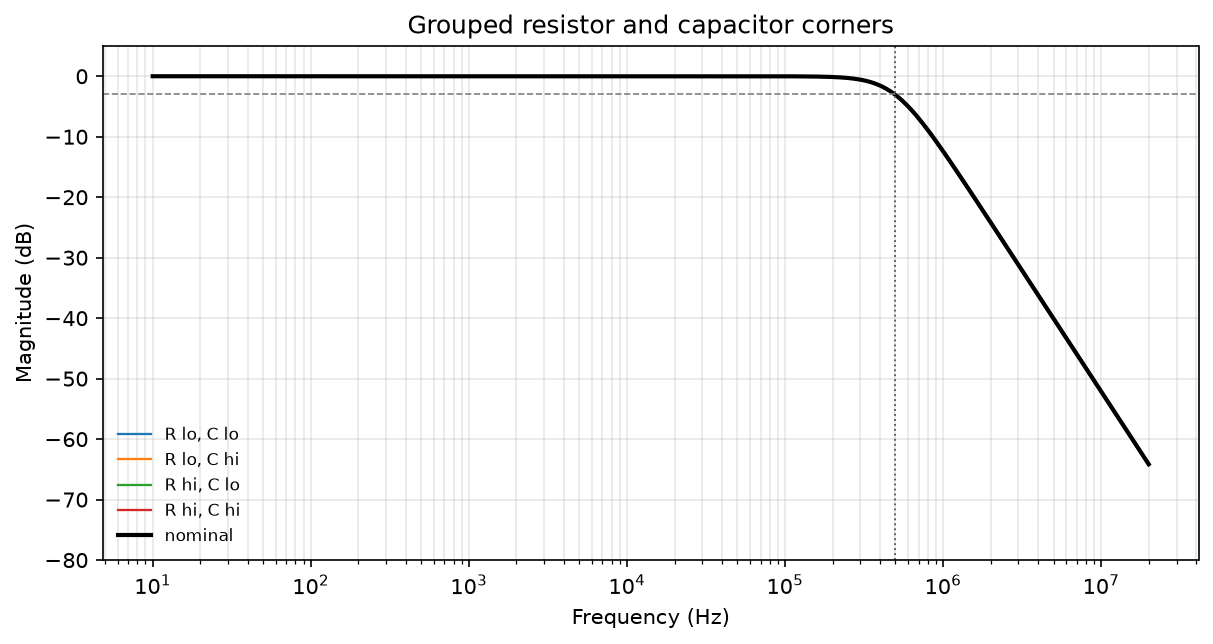

,corner,fc_spice_hz,fc_analytical_hz,fc_delta_Hz
0,R_lo_C_lo,500648.257249,500877.338788,-229.081539
1,R_lo_C_hi,490851.093057,490958.975644,-107.882587
2,R_hi_C_lo,499666.988698,499876.584864,-209.596166
3,R_hi_C_hi,489836.598379,489978.038629,-141.440251


In [4]:
from mfb_design.analysis import bode

f = np.logspace(np.log10(10), np.log10(20e6), 301)
fig, ax = plt.subplots(figsize=(8.2, 4.4))
for r_side, c_side in (("lo", "lo"), ("lo", "hi"), ("hi", "lo"), ("hi", "hi")):
    kw = {}
    for n in p.resistance_names():
        lo, hi = p.r_tol.bounds(getattr(p, n))
        kw[n] = lo if r_side == "lo" else hi
    for n in p.capacitance_names():
        lo, hi = p.c_tol.bounds(getattr(p, n))
        kw[n] = lo if c_side == "lo" else hi
    br = bode(p.with_values(**kw), f_hz=f)
    ax.semilogx(br.f_hz, br.mag_db, lw=1.1, label=f"R {r_side}, C {c_side}")
br0 = bode(p, f_hz=f)
ax.semilogx(br0.f_hz, br0.mag_db, "k-", lw=2.0, label="nominal")
ax.axhline(-3, color="0.5", ls="--", lw=0.8)
ax.axvline(p.op.f_design_hz, color="0.35", ls=":", lw=0.9)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude (dB)")
ax.set_ylim(-80, 5)
ax.set_title("Grouped resistor and capacitor corners")
ax.grid(True, which="both", alpha=0.3)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "04_wc_bode.png", dpi=150)
plt.show()

sp = spice_wc_corners(
    p,
    workdir=ROOT / "results" / "ngspice" / "nb04_wc",
    root=ROOT,
    opamp_model="ideal",
)
show = pd.DataFrame(sp).drop(columns=["params"])
show["fc_delta_Hz"] = show["fc_spice_hz"] - show["fc_analytical_hz"]
display(show)


## 32-corner transient hypercube

Each corner sets every resistor and every capacitor to one end of its
tolerance. The table is the full set, not a sample. ngspice fits the
waveform. LTspice reports `.four` over the same 60 µs to 100 µs window.


In [5]:
from mfb_design.transient import load_or_run_hypercube

hc = load_or_run_hypercube(
    p,
    root=ROOT,
    cache_csv=ROOT / "results" / "hypercube_tran.csv",
    workers=SPICE_WORKERS,
)
if not bool(hc["ng_ok"].all()) or not bool(hc["lt_ok"].all()):
    raise RuntimeError("hypercube cache is incomplete")
show = hc[[
    "corner", "an_gain", "ng_gain", "lt_gain",
    "an_phase_deg", "ng_phase_deg", "lt_phase_deg",
]].copy()
show["ng_gain_err"] = hc["ng_gain"] - hc["an_gain"]
show["lt_gain_err"] = hc["lt_gain"] - hc["an_gain"]
display(show)
ng_err = float((hc["ng_gain"] - hc["an_gain"]).abs().max())
lt_err = float((hc["lt_gain"] - hc["an_gain"]).abs().max())
print(f"max |ngspice − analytical| gain = {ng_err:.3e}")
print(f"max |LTspice − analytical| gain = {lt_err:.3e}")
print(f"corners {len(hc)}, gain {hc['an_gain'].min():.6f} to {hc['an_gain'].max():.6f}")
if ng_err > 1e-3 or lt_err > 1e-3:
    raise RuntimeError("a solver disagrees with the analytical corner gain")


,corner,an_gain,ng_gain,lt_gain,an_phase_deg,ng_phase_deg,lt_phase_deg,ng_gain_err,lt_gain_err
0,R1- R2- R3- C1- C2-,0.968521,0.968481,0.9685,136.872166,136.856607,136.87,-0.000040,-0.000021
1,R1- R2- R3- C1- C2+,0.962734,0.962690,0.9627,136.110339,136.094593,136.11,-0.000044,-0.000034
2,R1- R2- R3- C1+ C2-,0.971936,0.971897,0.9719,136.682626,136.666894,136.68,-0.000039,-0.000036
3,R1- R2- R3- C1+ C2+,0.966133,0.966090,0.9661,135.915412,135.899490,135.91,-0.000043,-0.000033
4,R1- R2- R3+ C1- C2-,0.970262,0.970221,0.9702,136.819658,136.804081,136.82,-0.000040,-0.000062
5,R1- R2- R3+ C1- C2+,0.964450,0.964405,0.9644,136.057253,136.041489,136.06,-0.000044,-0.000050
6,R1- R2- R3+ C1+ C2-,0.973686,0.973647,0.9736,136.629590,136.613840,136.63,-0.000039,-0.000086
7,R1- R2- R3+ C1+ C2+,0.967858,0.967815,0.9678,135.861790,135.845850,135.86,-0.000043,-0.000058
8,R1- R2+ R3- C1- C2-,0.968116,0.968076,0.9681,136.806619,136.791041,136.81,-0.000040,-0.000016
9,R1- R2+ R3- C1- C2+,0.962311,0.962267,0.9623,136.044196,136.028432,136.04,-0.000044,-0.000011


max |ngspice − analytical| gain = 4.452e-05
max |LTspice − analytical| gain = 1.021e-04
corners 32, gain 0.960767 to 0.973686


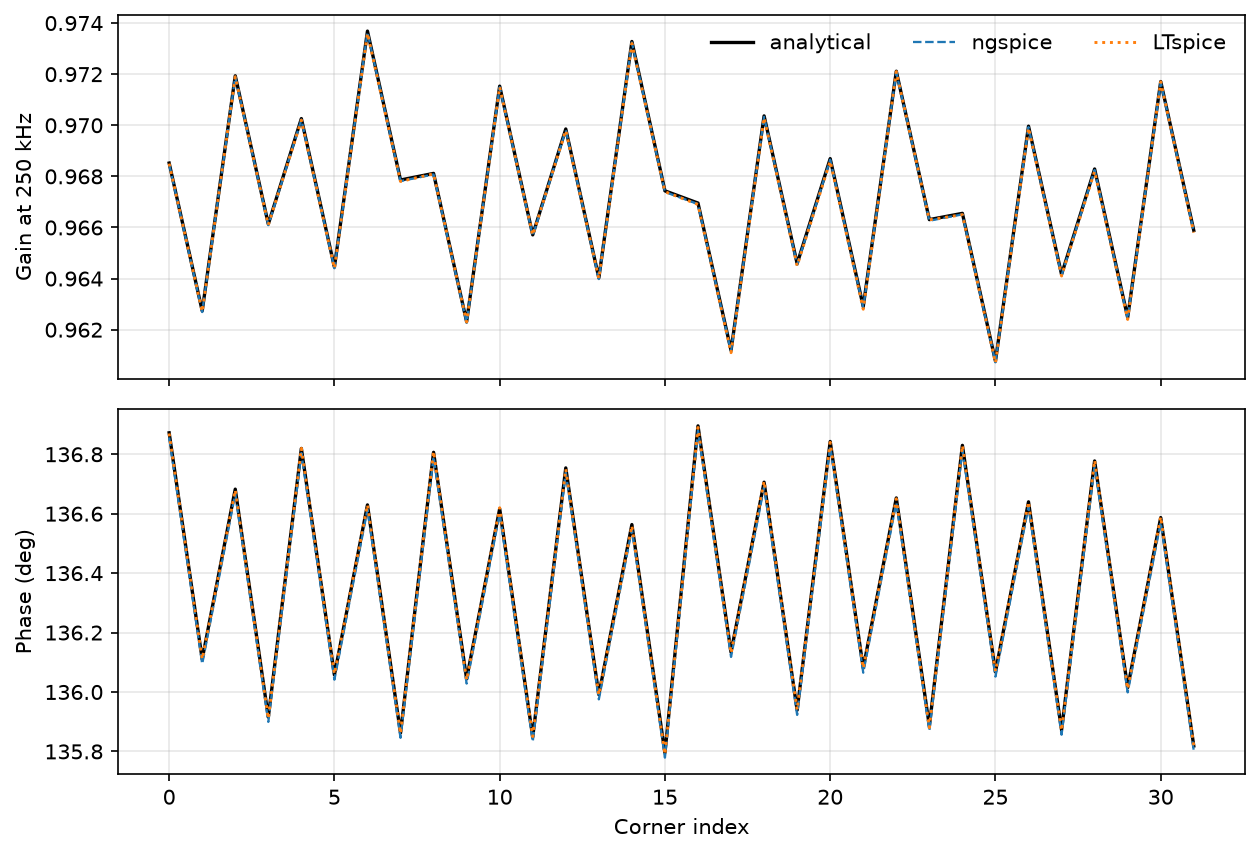

In [6]:
x = np.arange(len(hc))
fig, axes = plt.subplots(2, 1, figsize=(8.6, 5.8), sharex=True)
axes[0].plot(x, hc["an_gain"], "k-", lw=1.6, label="analytical")
axes[0].plot(x, hc["ng_gain"], "C0--", lw=1.1, label="ngspice")
axes[0].plot(x, hc["lt_gain"], "C1:", lw=1.4, label="LTspice")
axes[0].set_ylabel("Gain at 250 kHz")
axes[0].legend(frameon=False, ncol=3)
axes[0].grid(True, alpha=0.3)
axes[1].plot(x, hc["an_phase_deg"], "k-", lw=1.6, label="analytical")
axes[1].plot(x, hc["ng_phase_deg"], "C0--", lw=1.1, label="ngspice")
axes[1].plot(x, hc["lt_phase_deg"], "C1:", lw=1.4, label="LTspice")
axes[1].set_xlabel("Corner index")
axes[1].set_ylabel("Phase (deg)")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "04_hypercube.png", dpi=150)
plt.show()
